# Routes between two points

This notebook compares the four point-to-point searches of `shortest_path`, runs them for many pairs with `od_matrix(mode="pairwise")`, and contrasts the alternative routes of `alternative_paths` with the k shortest routes of `k_shortest_paths`. On a district graph of 22 thousand nodes every search takes about a millisecond; the differences between the methods grow with the graph, as the timings for the whole of Saint Petersburg on the routing page show.

In [1]:
# To install IduEdu in a clean environment:
# !pip install IduEdu

OSM_ID = 1114252  # Vasilyevsky Island, Saint Petersburg

In [2]:
import time

import numpy as np
import pandas as pd

import iduedu

walk = iduedu.get_walk_graph(osm_id=OSM_ID, clip_by_territory=True)
xs, ys = walk.nodes_gdf.geometry.x, walk.nodes_gdf.geometry.y
source = (xs - xs.quantile(0.2)).abs().add((ys - ys.median()).abs()).idxmin()
target = (xs - xs.quantile(0.85)).abs().add((ys - ys.quantile(0.3)).abs()).idxmin()
source, target

(np.int64(10924), np.int64(3642))

In [3]:
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
STREETS = "#d6d4ce"


def basemap(ax, graph, title):
    graph.edges_gdf.plot(ax=ax, color=STREETS, linewidth=0.4, zorder=1)
    ax.set_title(title)
    ax.set_axis_off()

## Four searches, one route

Every method returns a shortest route; they differ in how many nodes they visit. ALT builds its landmark tables on the first call and keeps them with the graph, so the first call is timed apart.

In [4]:
start = time.perf_counter()
iduedu.shortest_path(walk, source, target, weight='length_meter', method='alt')
print(f'first ALT call with the landmark tables: {time.perf_counter() - start:.2f} s')

rows = []
for method in ['dijkstra', 'bidirectional', 'astar', 'alt']:
    start = time.perf_counter()
    for _ in range(20):
        cost, route = iduedu.shortest_path(walk, source, target, weight='length_meter', method=method)
    rows.append({'method': method, 'length_m': round(cost, 1), 'nodes': len(route),
                 'ms_per_query': round((time.perf_counter() - start) / 20 * 1000, 2)})
pd.DataFrame(rows).set_index('method')

first ALT call with the landmark tables: 0.02 s


,length_m,nodes,ms_per_query
method,,,
dijkstra,4162.7,147,1.09
bidirectional,4162.7,147,1.01
astar,4162.7,147,1.57
alt,4162.7,147,0.13


## Many pairs

`od_matrix(mode="pairwise")` matches origins and destinations by position. `method` picks the search; the default `"auto"` runs the bidirectional search when most origins occur once.

In [5]:
rng = np.random.default_rng(0)
origins = rng.choice(walk.nodes_gdf.index, 500)
destinations = rng.choice(walk.nodes_gdf.index, 500)

for method in ['dijkstra', 'bidirectional', 'alt']:
    start = time.perf_counter()
    pairs = iduedu.od_matrix(walk, origins_nodes=origins, destination_nodes=destinations,
                             mode='pairwise', method=method, weight='length_meter')
    print(f'{method:>13}: {time.perf_counter() - start:.2f} s for 500 pairs')
pairs.head()

     dijkstra: 0.03 s for 500 pairs
bidirectional: 0.04 s for 500 pairs
          alt: 0.01 s for 500 pairs


,,dist
origin,destination,
19183,1912,3478.219482
14400,8642,3887.957764
11587,11533,2679.826172
6089,7354,1425.472656
6952,15705,4133.088379


## Alternative routes and k shortest routes

`k_shortest_paths` returns the next cheapest routes exactly; in a dense street graph they differ by a crossing or a sidewalk. `alternative_paths` penalises the streets of the routes already found and keeps routes that share at most `max_overlap` of their length with the others.

In [6]:
ranked = iduedu.k_shortest_paths(walk, source, target, 3, weight='length_meter')
alternatives = iduedu.alternative_paths(walk, source, target, 3, weight='length_meter')
print(ranked['dist'].round(1).to_dict())
alternatives[['dist', 'overlap']].round(3)

{0: 4162.7, 1: 4162.7, 2: 4162.7}


,dist,overlap
rank,,
0,4162.698,0.093
1,4226.962,0.060
2,4252.656,0.091


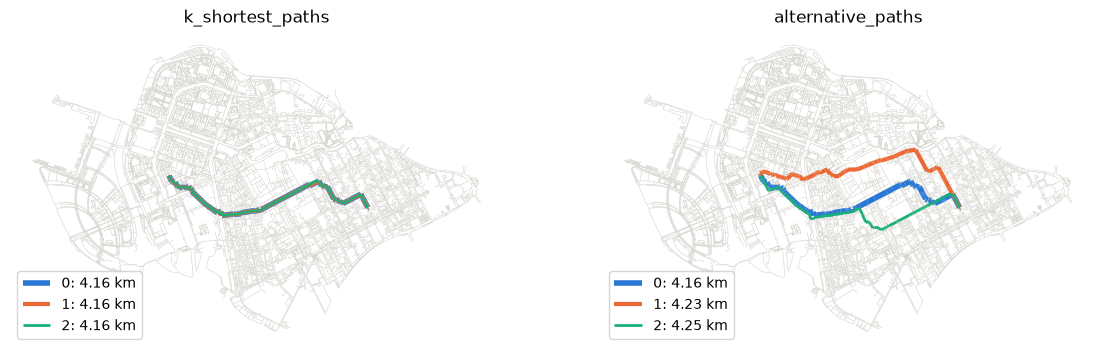

In [7]:
colours = [BLUE, ORANGE, AQUA]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, table, title in ((axes[0], ranked, 'k_shortest_paths'), (axes[1], alternatives, 'alternative_paths')):
    basemap(ax, walk, title)
    for (rank, row), colour in zip(table.iterrows(), colours):
        walk.path_to_edges(row['path'], weight='length_meter').plot(
            ax=ax, color=colour, linewidth=4 - rank, label=f'{rank}: {row["dist"] / 1000:.2f} km')
    ax.legend(loc='lower left')
plt.show()

## Your own area

Replace `OSM_ID` with the id of an OSM boundary relation, or pass `territory=` a shapely polygon in EPSG:4326 or a
GeoDataFrame. Measures near the border of a graph are biased, because the network beyond it is missing: build the
graph for a larger area and pass the study area as `area=` to `graph_stats` and `centrality`. For many runs on one
region, read a local OSM file instead of Overpass with `iduedu.use_pbf(...)` (see the data sources page).